In [54]:
import pandas as pd

In [55]:
import numpy as np

In [56]:
df = pd.read_csv('/content/placement.csv')

In [57]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [58]:

df.shape

(100, 4)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


# Preprosseing ke naam pe hum bs unnamed wala column hta **denga**

df.iloc[:,1:]
# iska mtlb ye hai ki mujhe mere datset mein se saare rows chaiye but ye jo column hai woo 1 onwards chiaye ya phir 1 ko choor kr sb chaiye rows column sb ***bold text***

Step 1 Preprosseing

In [60]:
df = df.iloc[:,1:]

In [61]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


Step 2 EDA

import matplotlib.pyplot as plt
we use this library for viewing the data

In [62]:
import matplotlib.pyplot as plt


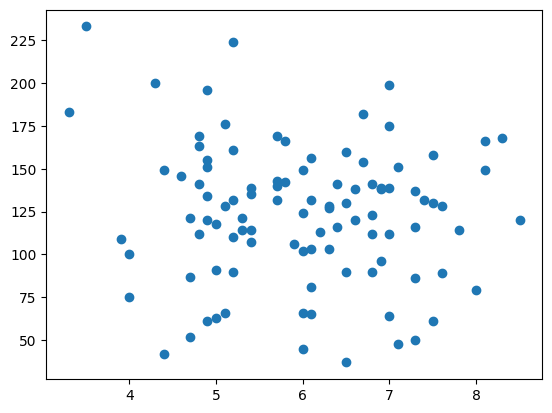

In [63]:
plt.scatter(df['cgpa'],df['iq'])
# x-axis pe Cgpa aur y-axis pe IQ

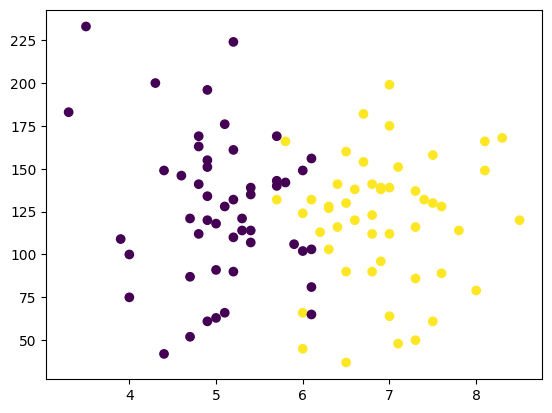

In [64]:
# agr dekhna hai kinka placment hua ha too use krenge ye

plt.scatter(df['cgpa'],df['iq'],c=df['placement'])

Isme yellow walo ka placment hoo gya aur blue walo ka nahi

# ***hum ek ml model bna rhe hai jo is data ke chupe huei pattern ko smjh paaye aur hum jo ml model bna rhe hai wo logstic regression h ***

# ***Logistic Regression line se kaatta hai data ko using a line they search a line which seprate both line logistic regression apne aap smjh ke kaam krega ki line kaisi hoogi woo linear data ke sath krta hai kaam ***

# ***EDA krne se smjh aaya ki data linear hai too dimmag mein idea bn gya ki hum logistic regression laga skte h***

Step 3 we will extract input and output columns

In [65]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


isme jo cgpa hai aur iq hai usei ml mein independent variable bolte hai kunki ye kisi pe depend nhi kr rha hai iq aur cgpa independent hai aur placement dependent varaible hai

In [66]:
x =df.iloc[:,0:2]
y=df.iloc[:,-1]

In [67]:
x

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [68]:
y

,placement
0,1
1,0
2,0
3,1
4,0
...,...
95,0
96,0
97,1
98,1


In [69]:
x.shape


(100, 2)

In [70]:
y.shape

(100,)

Step 4 Train test split

Train test split mein humei do cheezin deni hoti hai indepnedent variables dependent variables aur test_size
test size ka mtlb hai training mein kitna percent data jayega aur test mein kitna percent data jayega
agr humne likha test_size=0.1
to iska mtlb hai ki mai is function ko bol rha hu ki mere x aur y mein se 10 percent jo data hai out of 100
# basicslly 10 rows woo test mein chle jayenge aur 90 rows trainng mein chle jayenge **bold text** *italicized text

In [73]:
from sklearn.model_selection import train_test_split
train_test_split(x,y,test_size=0.1)

[    cgpa     iq
 52   7.0  175.0
 12   5.4  139.0
 62   6.0  102.0
 45   6.0   66.0
 75   4.8  169.0
 ..   ...    ...
 79   6.5   90.0
 4    5.8  142.0
 42   7.6   89.0
 6    5.7  143.0
 26   7.0  199.0
 
 [90 rows x 2 columns],
     cgpa     iq
 43   6.8  141.0
 16   5.2  224.0
 34   4.8  163.0
 0    6.8  123.0
 36   5.7  140.0
 61   7.3  137.0
 69   8.5  120.0
 66   6.9   96.0
 84   5.7  169.0
 48   6.6  138.0,
 52    1
 12    0
 62    0
 45    1
 75    0
      ..
 79    1
 4     0
 42    1
 6     0
 26    1
 Name: placement, Length: 90, dtype: int64,
 43    1
 16    0
 34    0
 0     1
 36    0
 61    1
 69    1
 66    1
 84    0
 48    1
 Name: placement, dtype: int64]

In [76]:
# training aur test ko dono ko varaibles mein store kr diya

In [77]:


x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.1)

In [78]:
x_train

,cgpa,iq
96,4.4,42.0
8,6.1,156.0
15,5.1,176.0
34,4.8,163.0
41,5.4,114.0
...,...,...
76,4.9,155.0
42,7.6,89.0
38,6.5,160.0
92,5.2,110.0


In [79]:
y_train

,placement
96,0
8,0
15,0
34,0
41,0
...,...
76,0
42,1
38,1
92,0


In [80]:
x_test

,cgpa,iq
93,6.8,112.0
32,7.0,139.0
3,7.4,132.0
59,4.8,112.0
33,6.0,149.0
9,5.1,66.0
57,6.5,130.0
53,8.3,168.0
48,6.6,138.0
62,6.0,102.0


In [81]:
y_test

,placement
93,1
32,1
3,1
59,0
33,0
9,0
57,1
53,1
48,1
62,0


Step 4 Scaling

In [82]:

from sklearn.preprocessing import StandardScaler

In [83]:
scaler = StandardScaler()


In [84]:
x_train=scaler.fit_transform(x_train)

In [86]:
x_train
# ab ye object se array bn gya

array([[-1.34827454, -1.99013506],
       [ 0.14008047,  0.79551101],
       [-0.73542248,  1.28422085],
       [-0.99807336,  0.96655946],
       [-0.47277159, -0.23077965],
       [-1.08562366, -0.89053792],
       [-0.21012071,  0.40454314],
       [ 2.24128755, -0.08416669],
       [-0.47277159,  0.38010765],
       [-0.21012071,  0.20905921],
       [ 1.19068401, -1.79465112],
       [-0.91052307,  0.25793019],
       [ 0.75293254,  0.42897863],
       [-0.73542248,  0.11131724],
       [-0.91052307, -0.08416669],
       [-0.47277159,  0.28236568],
       [ 0.75293254, -0.81723145],
       [-1.08562366, -1.74578014],
       [ 0.14008047, -1.42811875],
       [ 0.05253018,  0.01357527],
       [-0.21012071,  0.47784962],
       [-1.69847572, -0.57287653],
       [-0.82297277, -1.47698973],
       [ 0.75293254, -0.01086022],
       [ 0.14008047,  0.20905921],
       [ 1.01558342,  0.67333355],
       [ 0.31518106,  0.08688175],
       [ 1.62843549, -0.23077965],
       [-1.17317395,

In [87]:
# is baar hum transform use krenge kunki pattern humne trainnig ke time smjh liya hai
x_test=scaler.transform(x_test)

In [88]:
x_test

array([[ 0.75293254, -0.27965063],
       [ 0.92803313,  0.38010765],
       [ 1.27823431,  0.20905921],
       [-0.99807336, -0.27965063],
       [ 0.05253018,  0.62446257],
       [-0.73542248, -1.40368325],
       [ 0.49028165,  0.16018822],
       [ 2.06618696,  1.08873691],
       [ 0.57783195,  0.35567216],
       [ 0.05253018, -0.52400555]])

Step 5 Train the model

In [89]:
from sklearn.linear_model import LogisticRegression

In [90]:
clf = LogisticRegression ()

clf has power to use function which are is in logistic regression class whi pe ek function hota hai fit jo use krte hai model ko train krne ke liye bs humei apna training data provide karana hota hai

In [91]:
# model training
clf.fit(x_train,y_train)

LogisticRegression()

# Step 6 Evaluate the model
Evaluate the model mein kya hota hai isme hum
Accuracy nikl lete hai test wale data pe


In [92]:
clf.predict(x_test)

array([1, 1, 1, 0, 1, 0, 1, 1, 1, 1])

array([1, 1, 1, 0, 1, 0, 1, 1, 1, 1])




this is model predication

In [93]:
y_test

,placement
93,1
32,1
3,1
59,0
33,0
9,0
57,1
53,1
48,1
62,0


Accuracy chahe to khud se bhi likh skte hai ya sklearn ko use kr skte hai

In [101]:
y_pred = clf.predict(x_test)

In [102]:
from sklearn.metrics import accuracy_score

In [103]:
accuracy_score(y_test,y_pred)

0.8

0.8 mtlb accuracy 80% hai





desicion boundry mtlb ml model ne kya pattern observe kiya data mein usko visulize krne ke liye use krte hai

In [105]:
from mlxtend.plotting import plot_decision_regions



.values use kiya humne y_train mein numpy mein convert krne mein

<Axes: >

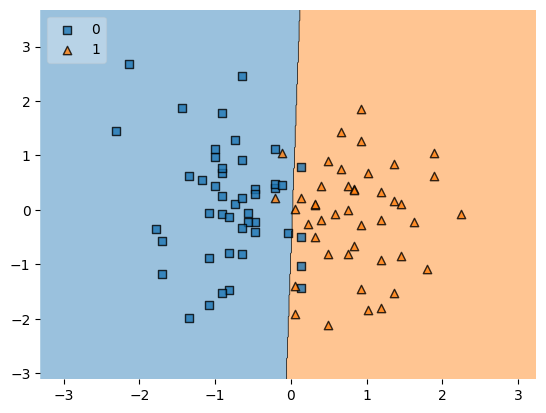

In [108]:
plot_decision_regions(x_train, y_train.values, clf=clf ,legend=2)

# **Step 7 Deploy the model**

# Pickle kya krta hai ?
# python mein everything is object too pickle object ko convert kr deta hai file mein

In [109]:
import pickle

In [110]:
pickle.dump(clf,open('model.pkl','wb'))